# 07 · HMM + Viterbi route reconstruction

**Input:** `data/features/*.parquet` (notebook 03), the tuned LightGBM (notebook 05) and tuned Random Forest (notebook 06).
**Output:** `outputs/hmm/` (results, decoder-tuning log, figures, Folium maps, `HMM_REPORT.md`) and `models/hmm_config.json`.
**Code:** `src/pathsnap/hmm.py` (states, emission, transition, Viterbi, path fill, `predict_trip`) and `src/pathsnap/maps.py`.

**Why an HMM:** the classifier scores each GPS fix on its own, so two neighbouring fixes can be matched to roads that are
not connected (the other direction of a two-way street, a parallel road). The HMM chooses one arc per fix so that the
whole sequence is both likely under the classifier and drivable on the directed road network.

**Protocol**
* Decoder parameters are tuned on **train only**, using **out-of-fold** classifier probabilities from the same 5
  GroupKFold folds (by trip, seed 42). So the HMM never sees probabilities from a model that was trained on the same trip.
* The final classifier + HMM combination is chosen from the CV results.
* student_test is decoded once at the end, for the final numbers. There is no evaluator-test data here.

In [1]:
import json, os, sys, time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.model_selection import GroupKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from pathsnap import hmm as H, maps as MP, training as T, tuning as TU
from pathsnap.cleaning import PROCESSED_ROOT, load_clean_trip

SMOKE = os.environ.get("PATHSNAP_SMOKE") == "1"          # quick test run: few decoder trials
OUT, MODELS, FEAT = ROOT / "outputs" / "hmm", ROOT / "models", ROOT / "data" / "features"
FIG, MAPS = OUT / "figures", OUT / "maps"
for d in (OUT, FIG, MAPS):
    d.mkdir(parents=True, exist_ok=True)

train = pd.read_parquet(FEAT / "train.parquet")
test = pd.read_parquet(FEAT / "student_test.parquet")
train_fx = pd.read_parquet(FEAT / "train_fixes.parquet")
test_fx = pd.read_parquet(FEAT / "student_test_fixes.parquet")

def load_part(part):
    arcs, routes, lens = {}, {}, {}
    for d in sorted((PROCESSED_ROOT / part).iterdir()):
        a = pd.read_csv(d / "arcs.csv.gz", usecols=["from_node", "to_node", "length_m"])
        arcs[d.name] = (a.from_node.to_numpy(), a.to_node.to_numpy())
        lens[d.name] = a.length_m.to_numpy()
        routes[d.name] = set(pd.read_csv(d / "route.csv.gz", usecols=["canonical_arc_id"]).canonical_arc_id)
    return arcs, routes, lens
arcs_tr, ref_tr, len_tr = load_part("train")
arcs_te, ref_te, len_te = load_part("student_test")
arcs = {**arcs_tr, **arcs_te}

# exactly the folds of notebooks 04-06
folds = list(GroupKFold(n_splits=T.N_FOLDS, shuffle=True, random_state=T.SEED).split(train, groups=train.trip_id.to_numpy()))
fold_of_trip = {tid: k for k, (_, va) in enumerate(folds) for tid in train.trip_id.iloc[va].unique()}
CLASSIFIERS = {"LightGBM_tuned": ROOT / "outputs" / "tuning" / "best_params.json",
               "RandomForest_tuned": ROOT / "outputs" / "tuning_rf" / "best_params.json"}
BUILD = {"LightGBM_tuned": TU.lgbm_spec, "RandomForest_tuned": TU.rf_spec}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d9d8d2", "grid.linewidth": 0.6, "figure.dpi": 110})
print(f"{train.trip_id.nunique()} train trips / {len(train_fx):,} fixes; {test.trip_id.nunique()} student_test trips / "
      f"{len(test_fx):,} fixes; excluded trips in student_test: {sorted(test_fx[test_fx.exclude_trip].trip_id.unique())}")

80 train trips / 208,417 fixes; 10 student_test trips / 19,160 fixes; excluded trips in student_test: []


## 1. Out-of-fold probabilities (train) and student_test probabilities
For each of the 5 folds, the tuned model is fitted on the other 4 folds (training rows `label_reliable & ~exclude_trip`,
as in notebooks 04-06) and predicts every candidate row of the held-out fold. Every train row then has a probability
from a model that never saw its trip. student_test uses the saved tuned models (fitted on all 80 train trips).

**Check:** the per-fold classifier Top-1 must reproduce the tuning notebooks exactly.

In [2]:
oof_path = FEAT / "hmm_oof_probs.parquet"                 # cache (git-ignored); recomputed on a full run
usable = T.training_mask(train)
if SMOKE and oof_path.exists():
    oof = pd.read_parquet(oof_path)
else:
    oof = pd.DataFrame(index=train.index)
    for name, bp in CLASSIFIERS.items():
        spec = BUILD[name](json.loads(bp.read_text())["params"])
        p = np.full(len(train), np.nan)
        for k, (tr_idx, va_idx) in enumerate(folds):
            model, fit_s, _ = T.fit_model(spec, train.iloc[tr_idx][usable[tr_idx]])
            p[va_idx], _ = T.predict(model, train.iloc[va_idx])
            print(f"{name} fold {k}: fit {fit_s:.0f}s", flush=True)
        oof[name] = p.astype(np.float32)
    oof.to_parquet(oof_path)

p_test = {name: T.predict(joblib.load(MODELS / f"{name}.joblib"), test)[0] for name in CLASSIFIERS}

check = {}
for name, bp in CLASSIFIERS.items():
    ours = [T.evaluate(train.iloc[va], train_fx[train_fx.trip_id.isin(set(train.trip_id.iloc[va]))],
                       oof[name].to_numpy()[va], arcs)["all_top1"] for _, va in folds]
    b = json.loads(bp.read_text())
    trials = pd.read_csv(bp.parent / "trials.csv").set_index("number")
    theirs = [trials.loc[b["trial"], f"fold{k}_all_top1"] for k in range(T.N_FOLDS)]
    check[name] = pd.Series(ours).round(6).tolist() == pd.Series(theirs).round(6).tolist()
    print(name, "per-fold OOF Top-1:", np.round(ours, 5), "| matches tuning notebook:", check[name])
assert all(check.values())

LightGBM_tuned fold 0: fit 32s


LightGBM_tuned fold 1: fit 28s


LightGBM_tuned fold 2: fit 12s


LightGBM_tuned fold 3: fit 12s


LightGBM_tuned fold 4: fit 12s


RandomForest_tuned fold 0: fit 34s


... (2 outputs left out)

RandomForest_tuned fold 3: fit 74s


RandomForest_tuned fold 4: fit 36s


LightGBM_tuned per-fold OOF Top-1: [0.85155 0.92743 0.88457 0.93188 0.85479] | matches tuning notebook: True


RandomForest_tuned per-fold OOF Top-1: [0.85436 0.92325 0.88491 0.93041 0.85408] | matches tuning notebook: True


## 2. Hidden states and pairwise route distances (built once per trip)
For every trip, `H.build_trip_hmm` collects each fix's candidate arcs (the hidden states) and, for every pair of
candidates of two consecutive fixes, the **driving distance** along directed arcs (distance-bounded Dijkstra, one
search per source node, cached for the trip). These do not depend on the decoder parameters, so the decoder search
below only re-scores them. Trips run in parallel.

In [3]:
COLS = ["fix_idx", "arc_id", "dist_m", "proj_t", "is_fallback"]
idx_tr = train.groupby("trip_id", sort=True).indices
idx_te = test.groupby("trip_id", sort=True).indices

def build_all(part, df, idx):
    jobs = [(part, tid, df.iloc[ix][COLS].reset_index(drop=True)) for tid, ix in idx.items()]
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
        return {h.trip_id: h for h in ex.map(H.build_trip_hmm_job, jobs)}

t0 = time.perf_counter()
hmm_tr = build_all("train", train, idx_tr)
hmm_te = build_all("student_test", test, idx_te)
build_wall = time.perf_counter() - t0
bs = pd.DataFrame([{"partition": part, "trip_id": t, "fixes": len(h.fix_idx), "pairs": h.n_pairs,
                    "carried_over": int((~h.in_chain).sum()), "chains": int(h.new_chain.sum()),
                    "no_path_share": float(np.isinf(h.pair_route).mean()) if h.n_pairs else 0.0, "build_s": h.build_s}
                   for part, hs in (("train", hmm_tr), ("student_test", hmm_te)) for t, h in hs.items()])
bs.to_csv(OUT / "state_space_per_trip.csv", index=False)
print(f"built {len(bs)} trips in {build_wall:.0f}s wall clock")
bs.groupby("partition")[["fixes", "pairs", "carried_over", "chains", "no_path_share", "build_s"]].agg(["sum", "mean", "max"]).round(3).T

built 90 trips in 11s wall clock


partition           student_test         train
fixes         sum      19160.000  2.084170e+05
              mean      1916.000  2.605212e+03
              max       3958.000  1.931300e+04
pairs         sum    2039912.000  1.683231e+07
              mean    203991.200  2.104038e+05
              max     541588.000  8.199400e+05
carried_over  sum          0.000  1.823000e+04
              mean         0.000  2.278750e+02
              max          0.000  1.651900e+04
chains        sum         11.000  1.210000e+02
              mean         1.100  1.512000e+00
              max          2.000  1.200000e+01
no_path_share sum          3.402  2.556700e+01
              mean         0.340  3.200000e-01
              max          0.636  7.580000e-01
build_s       sum          2.012  2.706400e+01
              mean         0.201  3.380000e-01
              max          0.382  1.400000e+00

## 3. Scoring helpers
Per-trip arrays (truth, masks, probabilities) are aligned to the fix order of each `TripHMM` once, so a decoder
trial only runs Viterbi and counts correct fixes. Full metrics use `H.score_predictions`.

In [4]:
def aligned(hs, fx, df, idx, probs):
    out = {}
    f = fx.set_index(["trip_id", "fix_idx"])
    for tid, h in hs.items():
        ft = f.loc[tid].loc[h.fix_idx]
        out[tid] = {"true": ft.true_arc.to_numpy(), "all": (ft.has_label & ~ft.exclude_trip).to_numpy(),
                    "p": {m: np.asarray(p)[idx[tid]] for m, p in probs.items()}}
    return out

al_tr = aligned(hmm_tr, train_fx, train, idx_tr, {m: oof[m].to_numpy() for m in CLASSIFIERS})
al_te = aligned(hmm_te, test_fx, test, idx_te, p_test)

def predict_all(hs, al, model, params=None):
    """params=None -> classifier only. Returns one row per fix: trip_id, fix_idx, pred_arc."""
    out = []
    for tid, h in hs.items():
        p = al[tid]["p"][model]
        arc = H.classifier_only(h, p) if params is None else H.decode(h, p, params)
        out.append(pd.DataFrame({"trip_id": tid, "fix_idx": h.fix_idx, "pred_arc": arc}))
    return pd.concat(out, ignore_index=True)

def pooled_top1(hs, al, model, params):
    ok = n = 0
    for tid, h in hs.items():
        a = al[tid]
        pred = H.decode(h, a["p"][model], params)
        ok += int((pred == a["true"])[a["all"]].sum()); n += int(a["all"].sum())
    return ok / n

t0 = time.perf_counter()
base = {m: pooled_top1(hmm_tr, al_tr, m, H.DEFAULT_PARAMS) for m in CLASSIFIERS}
one_decode_s = (time.perf_counter() - t0) / len(CLASSIFIERS)
print(f"default decoder, train OOF pooled Top-1: {base}; one full decode of train takes {one_decode_s:.1f}s")

default decoder, train OOF pooled Top-1: {'LightGBM_tuned': 0.9256591174487262, 'RandomForest_tuned': 0.9259003415513999}; one full decode of train takes 2.5s


## 4. Decoder parameter search (train out-of-fold probabilities only)
| parameter | range | meaning |
|---|---|---|
| `beta_m` | 1–100 m (log) | how strongly a mismatch between driving distance and GPS distance is penalised (cost = mismatch / beta) |
| `no_path_pen` | 2–50 (log) | cost of a transition with no path within the search bound (also the maximum mismatch cost) |
| `uturn_pen` | 0–20 | extra cost of switching to the reverse arc (a U-turn) |
| `stop_pen` | 0–20 | extra cost of changing arc while the car is stopped |
| `speed_pen` | 0–20 | extra cost if the implied driving speed is > 50 m/s (not applied on `is_fast_step` steps) |
| `p_floor` | 1e-6–1e-2 (log) | smallest probability used in log E; limits how strongly a near-zero classifier score vetoes a state |
| `use_dist`, `sigma_m` | on/off, 3–50 m | optional Gaussian distance term added to log E |

**Sampler:** Optuna TPE (seed 42), the same method as the classifier tuning; trial 0 is the hand-set default.
**Objective:** pooled out-of-fold Top-1 over all labelled fixes of the 78 non-excluded train trips.
Each classifier gets its own search, because the best decoder depends on how its probabilities are spread.
This search, on all 80 train trips, gives the **final** decoder. For an honest CV estimate, section 6 repeats the search
inside each fold (nested CV).

In [5]:
N_DEC_TRIALS = 3 if SMOKE else 60
optuna.logging.set_verbosity(optuna.logging.WARNING)

def tune_decoder(model, trips, name):
    # TPE search of the decoder parameters on the given train trips (out-of-fold probabilities)
    hs = {t: hmm_tr[t] for t in trips}
    st = optuna.create_study(study_name=name, direction="maximize", sampler=optuna.samplers.TPESampler(seed=T.SEED))
    st.enqueue_trial(H.DEFAULT_PARAMS)
    st.optimize(lambda tr: pooled_top1(hs, al_tr, model, TU.suggest(tr, H.SEARCH_SPACE)), n_trials=N_DEC_TRIALS)
    return st

dec_studies, dec_best = {}, {}
for m in CLASSIFIERS:
    t0 = time.perf_counter()
    st = tune_decoder(m, list(hmm_tr), f"hmm_{m}")
    dec_studies[m], dec_best[m] = st, st.best_params
    print(f"{m}: {len(st.trials)} trials in {(time.perf_counter() - t0) / 60:.1f} min; trial 0 {st.trials[0].value:.4f}, "
          f"best #{st.best_trial.number} {st.best_value:.4f}", flush=True)

log = pd.concat([st.trials_dataframe(attrs=("number", "value", "params", "duration")).assign(classifier=m)
                 for m, st in dec_studies.items()], ignore_index=True)
log.columns = [c.replace("params_", "") for c in log.columns]
log["duration_s"] = log.pop("duration").dt.total_seconds()
log.to_csv(OUT / "decoder_tuning_log.csv", index=False)
pd.DataFrame(dec_best).T

LightGBM_tuned: 60 trials in 2.4 min; trial 0 0.9257, best #53 0.9405


RandomForest_tuned: 60 trials in 2.3 min; trial 0 0.9259, best #26 0.9418


,beta_m,no_path_pen,uturn_pen,stop_pen,speed_pen,p_floor,use_dist,sigma_m
LightGBM_tuned,2.580119,46.639503,19.702142,19.167727,9.189935,0.000768,True,28.446468
RandomForest_tuned,3.740802,43.44638,17.239626,11.321652,5.729636,0.000023,True,32.841251


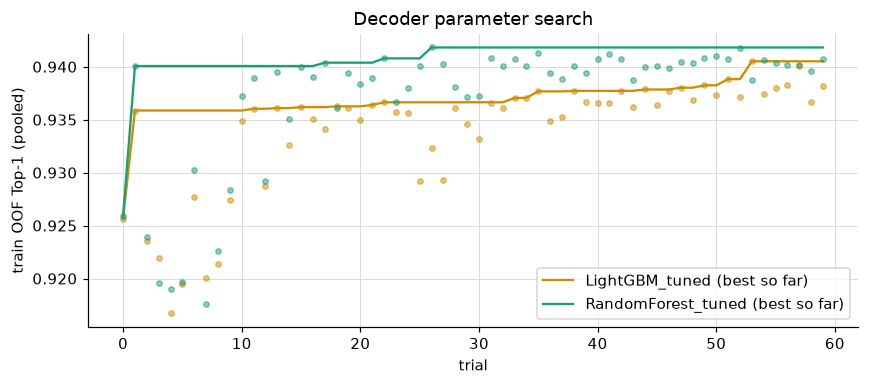

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for m, c in zip(CLASSIFIERS, ["#d08c00", "#1a9e77"]):
    v = log[log.classifier == m]["value"].to_numpy()
    ax.plot(v, "o", ms=3.5, color=c, alpha=0.5)
    ax.plot(np.maximum.accumulate(v), color=c, label=f"{m} (best so far)")
ax.set(xlabel="trial", ylabel="train OOF Top-1 (pooled)", title="Decoder parameter search")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "decoder_search.png", dpi=150)

## 5. Which parts of the decoder matter? (ablation, train OOF)
Starting from each model's final decoder, one part is switched off at a time (scored on the same train out-of-fold
probabilities the decoder was tuned on, so this shows which parts matter, not a test score).

In [7]:
ABLATIONS = {"best decoder": {}, "no U-turn penalty": {"uturn_pen": 0.0}, "no stop handling": {"stop_pen": 0.0},
             "no speed penalty": {"speed_pen": 0.0}, "Gaussian distance term flipped": "flip_dist",
             "classifier only (no HMM)": None}
abl = []
for m in CLASSIFIERS:
    for name, change in ABLATIONS.items():
        if change is None:
            pred = predict_all(hmm_tr, al_tr, m)
            v = pred.merge(train_fx, on=["trip_id", "fix_idx"]).pipe(
                lambda t: (t.pred_arc == t.true_arc)[t.has_label & ~t.exclude_trip].mean())
        else:
            prm = dict(dec_best[m])
            if change == "flip_dist":
                prm["use_dist"] = not prm["use_dist"]
                name = "Gaussian distance term " + ("added" if prm["use_dist"] else "removed")
            else:
                prm.update(change)
            v = pooled_top1(hmm_tr, al_tr, m, prm)
        abl.append({"classifier": m, "variant": name, "train OOF Top-1": v})
abl = pd.DataFrame(abl)
abl["vs best (pp)"] = 100 * (abl["train OOF Top-1"] - abl.groupby("classifier")["train OOF Top-1"].transform("first"))
abl.to_csv(OUT / "ablation.csv", index=False)
abl.round(4)

,classifier,variant,train OOF Top-1,vs best (pp)
0,LightGBM_tuned,best decoder,0.9405,0.0000
1,LightGBM_tuned,no U-turn penalty,0.9008,-3.9714
2,LightGBM_tuned,no stop handling,0.9334,-0.7072
3,LightGBM_tuned,no speed penalty,0.9402,-0.0269
4,LightGBM_tuned,Gaussian distance term removed,0.9405,-0.0049
5,LightGBM_tuned,classifier only (no HMM),0.8916,-4.8892
6,RandomForest_tuned,best decoder,0.9418,0.0000
7,RandomForest_tuned,no U-turn penalty,0.9021,-3.9736
8,RandomForest_tuned,no stop handling,0.9348,-0.7039
9,RandomForest_tuned,no speed penalty,0.9406,-0.1201


## 6. Classifier only vs classifier + HMM (nested CV, per fold)
For each fold, the held-out trips are scored with their out-of-fold probabilities, with and without the HMM.
**Nested CV:** the decoder used on fold k is tuned (same TPE search) on the other 4 folds only, so neither the
classifier nor the decoder has seen the scored trips. CV = mean ± std over the 5 folds, as in notebooks 04-06. Sequence metrics compare the set
of predicted arcs with the reference route arcs, weighted by length; "filled" uses the connected path.

In [8]:
NETS = {}
def network(part, tid):
    if (part, tid) not in NETS:
        c = load_clean_trip(part, tid)
        NETS[(part, tid)] = H.Network.from_frames(c["nodes"], c["arcs"])
    return NETS[(part, tid)]

def run(hs, al, part, model, params):
    # decode every trip and build the connected path (for the filled sequence metric and the maps)
    t0 = time.perf_counter()
    pred = predict_all(hs, al, model, params)
    dec_s = time.perf_counter() - t0
    filled = {tid: H.fill_path(h, network(part, tid), g.pred_arc.to_numpy())
              for (tid, g), h in zip(pred.groupby("trip_id", sort=False), hs.values())}
    return pred, filled, dec_s

cv_rows, preds, nested = [], {}, []
for m in CLASSIFIERS:
    parts = {"classifier only": [], "classifier + HMM": []}
    for k, (_, va) in enumerate(folds):
        val = sorted(set(train.trip_id.iloc[va]))
        fit_trips = [t for t in hmm_tr if t not in set(val)]
        prm = tune_decoder(m, fit_trips, f"hmm_{m}_fold{k}").best_params     # decoder tuned WITHOUT fold k
        nested.append({"classifier": m, "fold": k, **prm})
        hs_val = {t: hmm_tr[t] for t in val}
        for method, p_ in (("classifier only", None), ("classifier + HMM", prm)):
            pred, filled, _ = run(hs_val, al_tr, "train", m, p_)
            parts[method].append((pred, filled))
            s = H.score_predictions(pred, train_fx[train_fx.trip_id.isin(val)], train.iloc[va], arcs, ref_tr, len_tr, filled)
            cv_rows.append({"classifier": m, "method": method, "fold": k, **s})
        print(m, "fold", k, "done", flush=True)
    for method, lst in parts.items():
        preds[("cv", m, method)] = (pd.concat([p for p, _ in lst], ignore_index=True),
                                    {t: v for _, f in lst for t, v in f.items()})
pd.DataFrame(nested).to_csv(OUT / "nested_decoder_params.csv", index=False)
cv = pd.DataFrame(cv_rows)
cv.to_csv(OUT / "cv_per_fold.csv", index=False)
METRICS = ["all_top1", "reliable_top1", "all_sel_macro_f1", "reliable_sel_macro_f1", "route_continuity",
           "seq_all_precision", "seq_all_recall", "seq_all_f1", "seq_reliable_f1", "seq_filled_precision",
           "seq_filled_recall", "seq_filled_f1"]
cv_mean = cv.groupby(["classifier", "method"], sort=False)[METRICS].agg(["mean", "std"])
cv_mean.round(4).T

LightGBM_tuned fold 0 done


LightGBM_tuned fold 1 done


LightGBM_tuned fold 2 done


LightGBM_tuned fold 3 done


LightGBM_tuned fold 4 done


RandomForest_tuned fold 0 done


RandomForest_tuned fold 1 done


RandomForest_tuned fold 2 done


RandomForest_tuned fold 3 done


RandomForest_tuned fold 4 done


classifier                  LightGBM_tuned                   \
method                     classifier only classifier + HMM   
all_top1              mean          0.8900           0.9359   
                      std           0.0384           0.0321   
reliable_top1         mean          0.8942           0.9404   
                      std           0.0346           0.0276   
all_sel_macro_f1      mean          0.9388           0.9651   
                      std           0.0207           0.0171   
reliable_sel_macro_f1 mean          0.9399           0.9663   
                      std           0.0196           0.0159   
route_continuity      mean          0.9575           0.9783   
                      std           0.0144           0.0124   
seq_all_precision     mean          0.9054           0.9817   
                      std           0.0232           0.0084   
seq_all_recall        mean          0.9695           0.9725   
                      std           0.0058           0.0056   
seq_all_f1            mean          0.9363           0.9771   
                      std           0.0140           0.0058   
seq_reliable_f1       mean          0.9382           0.9790   
                      std           0.0137           0.0048   
seq_filled_precision  mean          0.8874           0.9814   
                      std           0.0279           0.0098   
seq_filled_recall     mean          0.9880           0.9915   
                      std           0.0100           0.0081   
seq_filled_f1         mean          0.9348           0.9864   
                      std           0.0164           0.0086   

classifier                 RandomForest_tuned                   
method                        classifier only classifier + HMM  
all_top1              mean             0.8894           0.9423  
                      std              0.0365           0.0252  
reliable_top1         mean             0.8935           0.9468  
                      std              0.0328           0.0207  
all_sel_macro_f1      mean             0.9384           0.9687  
                      std              0.0196           0.0133  
reliable_sel_macro_f1 mean             0.9395           0.9699  
                      std              0.0186           0.0120  
route_continuity      mean             0.9548           0.9782  
                      std              0.0148           0.0124  
seq_all_precision     mean             0.8981           0.9831  
                      std              0.0242           0.0076  
seq_all_recall        mean             0.9695           0.9727  
                      std              0.0054           0.0055  
seq_all_f1            mean             0.9323           0.9779  
                      std              0.0143           0.0053  
seq_reliable_f1       mean             0.9341           0.9798  
                      std              0.0141           0.0042  
seq_filled_precision  mean             0.8773           0.9829  
                      std              0.0280           0.0087  
seq_filled_recall     mean             0.9881           0.9919  
                      std              0.0094           0.0075  
seq_filled_f1         mean             0.9292           0.9874  
                      std              0.0164           0.0079

## 7. Choose the final classifier + HMM (from CV only)
The final pipeline is the classifier whose **HMM** output has the higher mean nested-CV Top-1 (all labelled fixes).

In [9]:
hmm_cv = cv[cv.method == "classifier + HMM"].groupby("classifier")["all_top1"].mean()
FINAL = hmm_cv.idxmax()
other = [m for m in CLASSIFIERS if m != FINAL][0]
paired = cv[cv.method == "classifier + HMM"].pivot(index="fold", columns="classifier", values="all_top1")
print(f"mean CV Top-1 with HMM: {hmm_cv.round(4).to_dict()} -> FINAL = {FINAL}; "
      f"ahead in {(paired[FINAL] > paired[other]).sum()} of 5 folds")
paired.round(4)

mean CV Top-1 with HMM: {'LightGBM_tuned': 0.9359, 'RandomForest_tuned': 0.9423} -> FINAL = RandomForest_tuned; ahead in 4 of 5 folds


classifier,LightGBM_tuned,RandomForest_tuned
fold,,
0,0.8932,0.9056
1,0.9684,0.9582
2,0.9221,0.9300
3,0.9675,0.9699
4,0.9286,0.9477


## 8. student_test (scored once, with the decoders chosen above)

In [10]:
test_rows, dec_time = [], []
for m in CLASSIFIERS:
    for method, prm in (("classifier only", None), ("classifier + HMM", dec_best[m])):
        pred, filled, _ = run(hmm_te, al_te, "student_test", m, prm)
        preds[("test", m, method)] = (pred, filled)
        s = H.score_predictions(pred, test_fx, test, arcs, ref_te, len_te, filled)
        test_rows.append({"classifier": m, "method": method, **s})
st_res = pd.DataFrame(test_rows).set_index(["classifier", "method"])
st_res.to_csv(OUT / "student_test_results.csv")

# decode time per trip (student_test, final decoder): state-space build (incl. Dijkstra) + Viterbi
for tid, h in hmm_te.items():
    c = load_clean_trip("student_test", tid)
    rows = test.iloc[idx_te[tid]][COLS].reset_index(drop=True)
    t0 = time.perf_counter(); hh = H.build_trip_hmm(tid, c["track"], network("student_test", tid), rows)
    t1 = time.perf_counter(); H.decode(hh, al_te[tid]["p"][FINAL], dec_best[FINAL]); t2 = time.perf_counter()
    dec_time.append({"trip_id": tid, "fixes": len(hh.fix_idx), "build_s": t1 - t0, "viterbi_s": t2 - t1})
dec_time = pd.DataFrame(dec_time)
dec_time["ms_per_1k_fixes"] = 1000 * (dec_time.build_s + dec_time.viterbi_s) / dec_time.fixes * 1000
dec_time.to_csv(OUT / "decode_time_student_test.csv", index=False)
print(dec_time[["build_s", "viterbi_s", "ms_per_1k_fixes"]].describe().round(3).loc[["mean", "50%", "max"]])
st_res[METRICS].round(4).T

      build_s  viterbi_s  ms_per_1k_fixes
mean    0.173      0.030          114.790
50%     0.155      0.019          110.860
max     0.367      0.084          169.673


classifier             LightGBM_tuned                  RandomForest_tuned  \
method                classifier only classifier + HMM    classifier only   
all_top1                       0.8961           0.9454             0.8992   
reliable_top1                  0.8972           0.9466             0.9003   
all_sel_macro_f1               0.9418           0.9696             0.9436   
reliable_sel_macro_f1          0.9422           0.9700             0.9439   
route_continuity               0.9597           0.9828             0.9550   
seq_all_precision              0.9292           0.9848             0.9243   
seq_all_recall                 0.9834           0.9841             0.9837   
seq_all_f1                     0.9555           0.9845             0.9530   
seq_reliable_f1                0.9555           0.9845             0.9530   
seq_filled_precision           0.9038           0.9830             0.8952   
seq_filled_recall              0.9957           0.9964             0.9960   
seq_filled_f1                  0.9475           0.9896             0.9429   

classifier                              
method                classifier + HMM  
all_top1                        0.9523  
reliable_top1                   0.9535  
all_sel_macro_f1                0.9735  
reliable_sel_macro_f1           0.9739  
route_continuity                0.9827  
seq_all_precision               0.9875  
seq_all_recall                  0.9849  
seq_all_f1                      0.9862  
seq_reliable_f1                 0.9862  
seq_filled_precision            0.9859  
seq_filled_recall               0.9972  
seq_filled_f1                   0.9915

## 9. Summary table

In [11]:
def fmt(m, method):
    r = {"CV Top-1 (all)": f"{cv_mean.loc[(m, method), ('all_top1', 'mean')]:.4f} ± {cv_mean.loc[(m, method), ('all_top1', 'std')]:.4f}",
         "CV Top-1 (reliable)": f"{cv_mean.loc[(m, method), ('reliable_top1', 'mean')]:.4f}"}
    for k, lab in [("all_sel_macro_f1", "CV macro F1 (selection)"), ("route_continuity", "CV route continuity"),
                   ("seq_all_f1", "CV sequence F1"), ("seq_filled_f1", "CV sequence F1 (filled path)")]:
        r[lab] = f"{cv_mean.loc[(m, method), (k, 'mean')]:.4f}"
    s = st_res.loc[(m, method)]
    r.update({"ST Top-1 (all)": f"{s.all_top1:.4f}", "ST Top-1 (reliable)": f"{s.reliable_top1:.4f}",
              "ST macro F1 (selection)": f"{s.all_sel_macro_f1:.4f}", "ST route continuity": f"{s.route_continuity:.4f}",
              "ST sequence P / R / F1": f"{s.seq_all_precision:.3f} / {s.seq_all_recall:.3f} / {s.seq_all_f1:.3f}",
              "ST sequence F1 (filled path)": f"{s.seq_filled_f1:.4f}"})
    return r
summary = pd.DataFrame({f"{m} · {meth}": fmt(m, meth) for m in CLASSIFIERS
                        for meth in ("classifier only", "classifier + HMM")}).T
summary.to_csv(OUT / "summary_table.csv")
summary.T

,LightGBM_tuned · classifier only,LightGBM_tuned · classifier + HMM,RandomForest_tuned · classifier only,RandomForest_tuned · classifier + HMM
CV Top-1 (all),0.8900 ± 0.0384,0.9359 ± 0.0321,0.8894 ± 0.0365,0.9423 ± 0.0252
CV Top-1 (reliable),0.8942,0.9404,0.8935,0.9468
CV macro F1 (selection),0.9388,0.9651,0.9384,0.9687
CV route continuity,0.9575,0.9783,0.9548,0.9782
CV sequence F1,0.9363,0.9771,0.9323,0.9779
CV sequence F1 (filled path),0.9348,0.9864,0.9292,0.9874
ST Top-1 (all),0.8961,0.9454,0.8992,0.9523
ST Top-1 (reliable),0.8972,0.9466,0.9003,0.9535
ST macro F1 (selection),0.9418,0.9696,0.9436,0.9735
ST route continuity,0.9597,0.9828,0.9550,0.9827


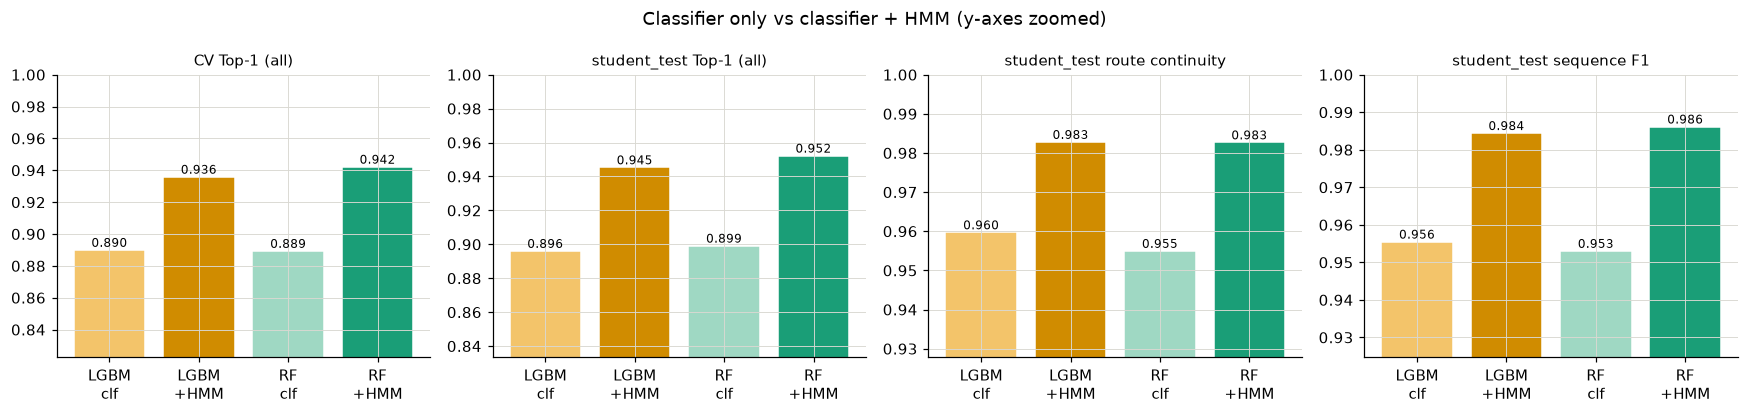

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
cols = {("LightGBM_tuned", "classifier only"): "#f3c46a", ("LightGBM_tuned", "classifier + HMM"): "#d08c00",
        ("RandomForest_tuned", "classifier only"): "#9fd8c3", ("RandomForest_tuned", "classifier + HMM"): "#1a9e77"}
panels = [("CV Top-1 (all)", lambda m, me: cv_mean.loc[(m, me), ("all_top1", "mean")]),
          ("student_test Top-1 (all)", lambda m, me: st_res.loc[(m, me), "all_top1"]),
          ("student_test route continuity", lambda m, me: st_res.loc[(m, me), "route_continuity"]),
          ("student_test sequence F1", lambda m, me: st_res.loc[(m, me), "seq_all_f1"])]
for ax, (title, f) in zip(axes, panels):
    vals = [f(*k) for k in cols]
    ax.bar(range(4), vals, color=list(cols.values()), edgecolor="white")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    lo = min(vals); ax.set_ylim(lo - (1 - lo) * 0.6, 1.0)
    ax.set_xticks(range(4), ["LGBM\nclf", "LGBM\n+HMM", "RF\nclf", "RF\n+HMM"]); ax.set_title(title, fontsize=10)
fig.suptitle("Classifier only vs classifier + HMM (y-axes zoomed)"); fig.tight_layout()
fig.savefig(FIG / "classifier_vs_hmm.png", dpi=150)

## 10. Where does the HMM help, and where not? (final classifier)
Every labelled fix that changed between classifier-only and HMM is put in one group, by how the WRONG arc relates to
the reference arc: the reverse direction of the same street, an arc that touches it (shares a node), or another road
(a parallel or nearby street).

In [13]:
def kind(wrong, true, fr, to):
    if wrong == true: return "correct"
    if fr[wrong] == to[true] and to[wrong] == fr[true]: return "reverse direction (two-way street)"
    if len({fr[wrong], to[wrong]} & {fr[true], to[true]}): return "touching arc (shares a node)"
    return "other road (parallel / nearby)"

def change_table(split, fx):
    a = preds[(split, FINAL, "classifier only")][0].rename(columns={"pred_arc": "clf"})
    b = preds[(split, FINAL, "classifier + HMM")][0].rename(columns={"pred_arc": "hmm"})
    t = a.merge(b, on=["trip_id", "fix_idx"]).merge(fx, on=["trip_id", "fix_idx"])
    t = t[t.has_label & ~t.exclude_trip & (t.clf != t.hmm)].copy()
    t["outcome"] = np.select([t.hmm == t.true_arc, t.clf == t.true_arc], ["fixed by HMM", "broken by HMM"], "wrong both ways")
    t["error kind"] = [kind(c if o == "fixed by HMM" else h, ta, *arcs[tid])
                       for tid, c, h, ta, o in zip(t.trip_id, t.clf, t.hmm, t.true_arc, t.outcome)]
    return t

chg_cv = change_table("cv", train_fx)
chg_te = change_table("test", test_fx)
helps = pd.concat({"CV (train OOF)": chg_cv.groupby(["outcome", "error kind"]).size(),
                   "student_test": chg_te.groupby(["outcome", "error kind"]).size()}, axis=1).fillna(0).astype(int)
helps.to_csv(OUT / "where_hmm_helps.csv")
helps

CV (train OOF)  \
outcome         error kind                                           
broken by HMM   other road (parallel / nearby)                 221   
                reverse direction (two-way street)             984   
                touching arc (shares a node)                   916   
fixed by HMM    other road (parallel / nearby)                1855   
                reverse direction (two-way street)            6846   
                touching arc (shares a node)                  2704   
wrong both ways other road (parallel / nearby)                 637   
                reverse direction (two-way street)             111   
                touching arc (shares a node)                   987   

                                                    student_test  
outcome         error kind                                        
broken by HMM   other road (parallel / nearby)                34  
                reverse direction (two-way street)           107  
                touching arc (shares a node)                 103  
fixed by HMM    other road (parallel / nearby)               245  
                reverse direction (two-way street)           661  
                touching arc (shares a node)                 355  
wrong both ways other road (parallel / nearby)                21  
                reverse direction (two-way street)            19  
                touching arc (shares a node)                 126

In [14]:
# stopped vs moving fixes (is_stop from cleaning), CV
track_flags = pd.concat([load_clean_trip("train", t)["track"][["fix_idx", "is_stop"]].assign(trip_id=t) for t in hmm_tr])
a = preds[("cv", FINAL, "classifier only")][0].rename(columns={"pred_arc": "clf"})
b = preds[("cv", FINAL, "classifier + HMM")][0].rename(columns={"pred_arc": "hmm"})
t = a.merge(b, on=["trip_id", "fix_idx"]).merge(train_fx, on=["trip_id", "fix_idx"]).merge(track_flags, on=["trip_id", "fix_idx"])
t = t[t.has_label & ~t.exclude_trip]
by_stop = t.groupby("is_stop").apply(lambda g: pd.Series({"fixes": len(g), "classifier Top-1": (g.clf == g.true_arc).mean(),
                                                           "HMM Top-1": (g.hmm == g.true_arc).mean()}), include_groups=False)
by_stop.to_csv(OUT / "stop_vs_moving_cv.csv")
by_stop.round(4)

,fixes,classifier Top-1,HMM Top-1
is_stop,,,
False,162616.0,0.9293,0.9687
True,19787.0,0.5738,0.7191


CV: HMM better in 73, worse in 5 of 78 trips; student_test: better in 9, worse in 1 of 10


,fixes,classifier,HMM,gain_pp
trip_id,,,,
00000052,262.0,0.9771,0.9504,-2.6718
00000000,2503.0,0.9549,0.9776,2.2773
00000007,1354.0,0.9705,0.9956,2.5111
00000065,768.0,0.8672,0.8958,2.8646
00000009,1049.0,0.8827,0.9161,3.3365
00000040,2995.0,0.9469,0.9853,3.8397
00000091,874.0,0.9027,0.9428,4.0046
00000056,3955.0,0.9120,0.9522,4.0202
00000076,1486.0,0.9253,0.9771,5.1817


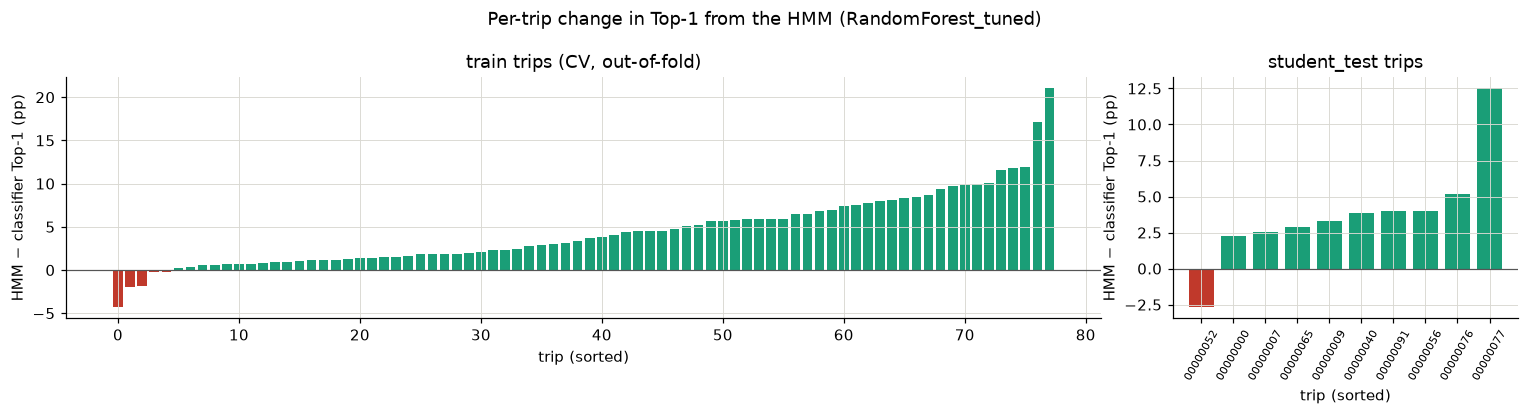

In [15]:
def per_trip(split, fx):
    a = preds[(split, FINAL, "classifier only")][0].rename(columns={"pred_arc": "clf"})
    b = preds[(split, FINAL, "classifier + HMM")][0].rename(columns={"pred_arc": "hmm"})
    t = a.merge(b, on=["trip_id", "fix_idx"]).merge(fx, on=["trip_id", "fix_idx"])
    t = t[t.has_label & ~t.exclude_trip]
    g = t.groupby("trip_id").apply(lambda g: pd.Series({"fixes": len(g), "classifier": (g.clf == g.true_arc).mean(),
                                                        "HMM": (g.hmm == g.true_arc).mean()}), include_groups=False)
    g["gain_pp"] = 100 * (g.HMM - g.classifier)
    return g.sort_values("gain_pp")
pt_cv, pt_te = per_trip("cv", train_fx), per_trip("test", test_fx)
pt_cv.to_csv(OUT / "per_trip_cv.csv"); pt_te.to_csv(OUT / "per_trip_student_test.csv")
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [3, 1]})
for ax, g, title in ((axes[0], pt_cv, "train trips (CV, out-of-fold)"), (axes[1], pt_te, "student_test trips")):
    ax.bar(range(len(g)), g.gain_pp, color=np.where(g.gain_pp >= 0, "#1a9e77", "#c0392b"))
    ax.axhline(0, color="#555", lw=0.8)
    ax.set(title=title, ylabel="HMM − classifier Top-1 (pp)", xlabel="trip (sorted)")
    if len(g) <= 12:
        ax.set_xticks(range(len(g)), g.index, rotation=60, fontsize=7)
fig.suptitle(f"Per-trip change in Top-1 from the HMM ({FINAL})"); fig.tight_layout()
fig.savefig(FIG / "per_trip_gain.png", dpi=150)
print(f"CV: HMM better in {(pt_cv.gain_pp > 0).sum()}, worse in {(pt_cv.gain_pp < 0).sum()} of {len(pt_cv)} trips; "
      f"student_test: better in {(pt_te.gain_pp > 0).sum()}, worse in {(pt_te.gain_pp < 0).sum()} of {len(pt_te)}")
pt_te.round(4)

## 11. Folium maps (student_test)
Three trips: the largest HMM gain, the smallest gain, and the median one. Layers: road network near the track, raw GPS,
reference route, classifier-only arcs (the arc of each fix) and the connected HMM route. Use the layer control (top
right) to switch layers on and off.

In [16]:
pick = {"largest_gain": pt_te.index[-1], "smallest_gain": pt_te.index[0], "median_gain": pt_te.index[len(pt_te) // 2]}
for label, tid in pick.items():
    c = load_clean_trip("student_test", tid)
    clf = preds[("test", FINAL, "classifier only")][0]
    hm_fill = preds[("test", FINAL, "classifier + HMM")][1][tid]
    g = pt_te.loc[tid]
    title = (f"student_test trip {tid}: Top-1 classifier {g.classifier:.3f} → HMM {g.HMM:.3f} ({FINAL})")
    m = MP.trip_map(title, c["track"], c["nodes"], c["arcs"], c["route"]["canonical_arc_id"].tolist(),
                    clf[clf.trip_id == tid].pred_arc.tolist(), hm_fill)
    m.save(MAPS / f"trip_{tid}_{label}.html")
    print(label, tid, "->", (MAPS / f"trip_{tid}_{label}.html").relative_to(ROOT))

largest_gain 00000077 -> outputs\hmm\maps\trip_00000077_largest_gain.html


smallest_gain 00000052 -> outputs\hmm\maps\trip_00000052_smallest_gain.html


median_gain 00000040 -> outputs\hmm\maps\trip_00000040_median_gain.html


## 12. Inference function for the API, and the saved configuration
`H.predict_trip(partition, trip_id, model, params)` runs the whole pipeline from the **raw** files (`.track`, `.nodes`,
`.arcs` only; the `.route` file is not read). It is checked here against the notebook's decoding of two student_test trips.

In [17]:
cfg = {"classifier": FINAL, "classifier_file": f"models/{FINAL}.joblib", "decoder_params": dec_best[FINAL],
       "constants": {"MIN_DETOUR_M": H.MIN_DETOUR_M, "V_MAX_MPS": H.V_MAX_MPS},
       "candidates": {"radius_m": 50.0, "max_candidates": 16},
       "selected_by": "highest mean nested-CV Top-1 (all labelled fixes) of classifier + HMM, train out-of-fold probabilities",
       "cv_top1_hmm": {m: round(float(v), 4) for m, v in hmm_cv.items()},
       "decoder_params_other_classifier": {other: dec_best[other]}}
(MODELS / "hmm_config.json").write_text(json.dumps(cfg, indent=1, default=str), encoding="utf-8")

final_model = joblib.load(MODELS / f"{FINAL}.joblib")
api_check = []
for tid in [pick["largest_gain"], pick["smallest_gain"]]:
    res = H.predict_trip("student_test", tid, final_model, dec_best[FINAL])
    nb = preds[("test", FINAL, "classifier + HMM")][0]
    nb = nb[nb.trip_id == tid].set_index("fix_idx").pred_arc
    same = (res["fixes"].set_index("fix_idx").pred_arc_hmm == nb.loc[res["fixes"].fix_idx]).mean()
    api_check.append({"trip_id": tid, "fixes": len(res["fixes"]), "same_as_notebook": float(same),
                      "path_pieces": len(res["path"]), **{k: round(v, 2) for k, v in res["timing"].items()}})
api_check = pd.DataFrame(api_check)
api_check.to_csv(OUT / "predict_trip_check.csv", index=False)
api_check

,trip_id,fixes,same_as_notebook,path_pieces,clean_features_s,classifier_s,hmm_build_s,viterbi_s,total_s
0,00000077,3911,1.0,1,0.59,0.13,0.29,0.05,1.07
1,00000052,262,1.0,1,0.18,0.09,0.03,0.00,0.30


## 13. Write `HMM_REPORT.md`

In [18]:
def md_table(df):
    return df.to_markdown()
dp = pd.DataFrame(dec_best).T
s_f, s_o = st_res.loc[(FINAL, "classifier + HMM")], st_res.loc[(FINAL, "classifier only")]
c_f = cv_mean.loc[(FINAL, "classifier + HMM")]; c_o = cv_mean.loc[(FINAL, "classifier only")]
n_tr = {m: len(st.trials) for m, st in dec_studies.items()}
L = ["# PathSnap: HMM + Viterbi route reconstruction", "",
     "Auto-generated by `notebooks/07_hmm_viterbi.ipynb` (seed 42). Every number comes from that run. Code: "
     "`src/pathsnap/hmm.py`.", "",
     "## 1. What are the hidden states?", "",
     "For every GPS fix, its **candidate arcs**: the directed road arcs within 50 m (at most 16, geometric duplicates "
     "merged into one canonical arc), produced by `candidates.py`. The state *is* the canonical arc id that is scored, "
     "so the candidate → road-segment correspondence is kept exactly. Mean candidates per fix: "
     f"{len(train) / len(train_fx):.1f} (train), {len(test) / len(test_fx):.1f} (student_test).", "",
     "## 2. How are emission probabilities calculated?", "",
     "log E = log max(p, p_floor), where p is the tuned classifier's probability that this candidate is the true arc. "
     "An optional Gaussian distance term −(d/σ)²/2 was part of the search (`use_dist`); the ablation below shows "
     "whether it helps. The emission weight is fixed at 1, because only the balance between emission and transition "
     "costs changes the Viterbi path, and β already sets it.", "",
     "## 3. How are transition probabilities calculated?", "",
     "log A(i→j) = −cost, with cost = min(|route − gps| / β, no_path_pen) + U-turn, stop and speed penalties. "
     "*route* is the driving distance along **directed** arcs from the point on arc i to the point on arc j: on the same "
     "arc it is the forward distance (backward jitter counts as standing still); to the reverse arc it is a U-turn on "
     "the spot (allowed, with `uturn_pen`); otherwise the rest of arc i + the shortest path + the start of arc j. "
     f"Shortest paths use Dijkstra bounded at gps + max({H.MIN_DETOUR_M:.0f} m, gps), one search per source node, cached "
     "per trip. *gps* is the straight-line distance between the two fixes. `stop_pen` is added when both fixes are in "
     f"the same stop and the arc changes; `speed_pen` when route/dt > {H.V_MAX_MPS:.0f} m/s, except on steps flagged "
     "`is_fast_step` (raw GPS speed there is not trustworthy).", "",
     "**Decoder parameters** were tuned on train out-of-fold probabilities only (Optuna TPE, seed 42, "
     f"{', '.join(f'{v} trials for {k}' for k, v in n_tr.items())}, objective = pooled OOF Top-1). Final values (search on all 80 train trips):", "", md_table(dp), "",
     "CV numbers below are **nested**: on each fold, the decoder was re-tuned on the other 4 folds "
     "(`nested_decoder_params.csv`).", "",
     "## 4. How are missing candidates or large GPS gaps handled?", "",
     "* **Gaps > 120 s** (`segment_id` changes): a new Viterbi chain starts, because a shortest path between fixes "
     f"that far apart is not a safe assumption. Chains: {int(bs[bs.partition == 'train'].chains.sum())} in train, "
     f"{int(bs[bs.partition == 'student_test'].chains.sum())} in student_test.",
     "* **No candidate within 50 m:** the fix only has its fallback nearest arc. It is left out of the chain (the chain is "
     "carried over it, from the fix before to the fix after), predicted as that nearest arc and flagged `carried_over`. "
     f"Such fixes: {int(bs[bs.partition == 'train'].carried_over.sum())} in train, "
     f"{int(bs[bs.partition == 'student_test'].carried_over.sum())} in student_test.",
     "* **Stops:** while the car is stopped, changing arc costs `stop_pen`, so GPS jitter does not move the match around.", "",
     "## 5. What happens when consecutive fixes suggest disconnected road segments?", "",
     "If there is no directed path within the search bound, the transition gets the large but **finite** cost "
     f"`no_path_pen`. Viterbi never sees −inf, so a chain always continues. Share of candidate pairs with no path: "
     f"{bs[bs.partition == 'train'].no_path_share.mean():.1%} (train, mean per trip). For the map, consecutive arcs are "
     "joined by the shortest path; where none exists, the drawn route starts a new piece.", "",
     "## 6. Did HMM decoding improve the route?", "",
     f"Final pipeline: **{FINAL} + HMM** (chosen by mean nested-CV Top-1 with HMM: "
     + ", ".join(f"{m} {v:.4f}" for m, v in hmm_cv.items()) + ").", "",
     md_table(summary), "",
     "Ablation (train OOF, pooled Top-1, one part switched off at a time):", "", md_table(abl.round(4).set_index(["classifier", "variant"])), "",
     f"Fixes that changed ({FINAL}), by outcome and by how the wrong arc relates to the reference arc:", "",
     md_table(helps), "",
     "Stopped vs moving fixes (CV):", "", md_table(by_stop.round(4)), "",
     "Per student_test trip:", "", md_table(pt_te.round(4)), "",
     "Decode time per student_test trip (state-space build incl. Dijkstra + Viterbi):", "",
     md_table(dec_time.set_index("trip_id").round(3)), "",
     "`predict_trip` (raw files → route) check against the notebook:", "", md_table(api_check.set_index("trip_id")), "",
     "## Figures and maps", "",
     *[f"![{p.stem}](figures/{p.name})" for p in sorted(FIG.glob("*.png"))], "",
     *[f"* [{p.stem}](maps/{p.name})" for p in sorted(MAPS.glob("*.html"))]]
(OUT / "HMM_REPORT.md").write_text("\n".join(L) + "\n", encoding="utf-8")
print("wrote", OUT / "HMM_REPORT.md")

wrote C:\College\sem-v\ml\ml_hackathon\PATHSNAP\outputs\hmm\HMM_REPORT.md


## Reading the results (written after this run)

* **The HMM is the biggest single improvement in the project.** With the final pipeline (tuned Random Forest + HMM),
  nested-CV Top-1 rises from 0.8894 to 0.9423 (+5.3 pp) and student_test Top-1 from 0.8992 to 0.9523 (+5.3 pp).
  The HMM is better than the classifier alone in all 5 folds, for both classifiers. Route continuity goes from 0.955
  to 0.983 on student_test. Sequence F1 goes from 0.953 to 0.986, mostly through precision (0.924 to 0.987): the
  classifier alone scatters fixes onto arcs that are not on the route, and the HMM removes most of them.
* **Why Random Forest + HMM was chosen:** it has the higher mean nested-CV Top-1 with the HMM (0.9423 vs 0.9359 for
  LightGBM), is ahead in 4 of 5 folds, and also has a lower fold-to-fold spread (± 0.025 vs ± 0.032). It is ahead on
  student_test too (0.9523 vs 0.9454), but the choice was made from CV only. Without the HMM the two classifiers were
  tied. With it they separate, so the decoder changes which classifier is better. LightGBM has the better log loss, so
  this shows that log loss alone did not predict which model works best inside the HMM.
* **What does the work:** the ablation (train out-of-fold) shows that the **U-turn penalty** matters most. Without it,
  Top-1 drops by about 4 pp, because the HMM then switches freely to the reverse arc of a two-way street. **Stop
  handling** is next (about 0.7 pp). The speed penalty (0.03–0.12 pp) and the Gaussian distance term (≤ 0.03 pp) add
  almost nothing, because the classifier already uses distance and the speed check rarely fires at 1 Hz.
* **Where the HMM helps:** most fixes it corrects were on the **reverse direction of a two-way street**: 6,846 in CV
  and 661 on student_test. The classifier cannot tell the two directions apart from one noisy fix, but the sequence
  can. Next come arcs that touch the true arc (2,704 / 355) and parallel or nearby roads (1,855 / 245). On stopped
  fixes, classifier Top-1 is only 0.574 and the HMM lifts it to 0.719. The parked jitter leaves the heading
  meaningless, so the sequence is the only signal.
* **Where it does not help:** for every 5 fixes the HMM corrects, it breaks about 1 (2,121 broken vs 11,405 fixed in
  CV; 244 vs 1,261 on student_test). These are mostly the same two cases: reverse direction (984) and touching arcs
  (916). 5 of 78 train trips and 1 of 10 student_test trips got worse. Another 1,735 CV fixes changed from one wrong arc
  to another wrong arc.
* **Example where it helps (student_test trip 77):** Top-1 goes from 0.784 to 0.910 (+12.5 pp), the largest gain. The
  car is stopped for 40 % of the trip. The classifier flips between the two directions of the street while it is
  parked, and the HMM keeps one consistent arc. Of the 610 fixes it corrects, 487 were on the reverse direction and
  443 were during stops. It also breaks 120 fixes (100 reverse direction, 102 during stops), so stops are where it
  both helps and hurts the most.
* **Example where it does not help (student_test trip 52):** a short trip (262 fixes) where Top-1 goes from 0.977 to
  0.950 (−2.7 pp). All 9 broken fixes are between fix 22 and fix 50, during a stop near a junction. The stop penalty
  keeps the car on one arc, but the reference labels move to the next (touching) arc during that stop. The stop
  detector (less than 30 m of movement over 60 fixes) may also catch slow driving through a junction, and then a strong
  stop penalty is wrong. On such a short trip, 9 fixes is already 2.7 pp.
* **Boundary values:** in all 12 decoder searches (final and nested, both classifiers), `uturn_pen` ended at 17–20,
  near the top of its 0–20 range. `stop_pen` (10–20) is also high. A wider range might gain a little more, but the
  ablation suggests most of the effect is already captured. `use_dist` was always chosen as True, but its effect is
  negligible.
* **Honesty notes:** the CV numbers are nested (the decoder was re-tuned without the scored fold). The ablation and the
  "where it helps" counts use the decoder tuned on all train trips, so they describe the decoder rather than test it.
  On average 32 % of candidate pairs have no path within the search bound, mostly pairs whose arcs point in opposite
  directions. They get the finite `no_path_pen`, so no chain ever breaks.
* **Speed:** the HMM stage (state space with Dijkstra + Viterbi) takes 64–170 ms per 1,000 fixes on student_test, at
  most 0.45 s for a trip. The whole `predict_trip` from raw files takes 1.1 s for the 3,911-fix trip 77. It gives
  exactly the same arcs as the notebook (`same_as_notebook` = 1.0).
